### Quick Start: Loading the Saved Model and Running Inference

To run inference on your fine-tuned model immediately:
1. Ensure your model weight file (`resnet50_fine_tuned_birds.pth`) is uploaded to this workspace.
2. Execute the setup cells below to reconstruct the ResNet50 model architecture and load the weights.
3. Provide a path to a bird image in the prediction function.

In [ ]:
import os
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image

# 1. Define active device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Reconstruct the model architecture configured for 200 classes
model_inference = models.resnet50(weights=None)
num_features = model_inference.fc.in_features
model_inference.fc = nn.Linear(num_features, 200)

# 3. Load the saved fine-tuned state dictionary safely (pointing to the correct exported weights file)
weights_path = 'resnet50_cub200_weights.pth'
if os.path.exists(weights_path):
    state_dict = torch.load(weights_path, map_location=device)
    model_inference.load_state_dict(state_dict)
    model_inference = model_inference.to(device)
    model_inference.eval()
    print("Model weights loaded successfully! Ready for inference.")
else:
    print(f"Error: Weight file not found at '{weights_path}'. Please run the final cell to save the model weights first.")

### Single Image Inference Function

In [ ]:
def predict_bird(image_path, model, device):
    # Replicate the validation data transformation pipeline
    inference_transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    # Open the image
    image = Image.open(image_path).convert("RGB")

    # Apply transforms and add batch dimension [C, H, W] -> [1, C, H, W]
    input_tensor = inference_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, 1)

    return predicted_idx.item(), confidence.item()

# Example Usage:
# test_image = "your_local_bird_image.jpg"
# if os.path.exists(test_image):
#     class_id, confidence = predict_bird(test_image, model_inference, device)
#     print(f"Predicted Class Index: {class_id} (Label class: {class_id + 1})")
#     print(f"Confidence: {confidence * 100:.2f}%")

### Exporting Standalone Script: `predict.py`

The block below automatically outputs a CLI script allowing users to run predictions locally outside this notebook.

In [ ]:
predict_script_content = """
import os
import argparse
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image

def get_model(weights_path, device):
    model = models.resnet50(weights=None)
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 200)

    if os.path.exists(weights_path):
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        model = model.to(device)
        model.eval()
        return model
    else:
        raise FileNotFoundError(f"No weight file found at '{weights_path}'")

def predict(image_path, model, device):
    inference_transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    image = Image.open(image_path).convert("RGB")
    input_tensor = inference_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, 1)
    return predicted_idx.item(), confidence.item()

if __name__ == '__main__':
    parser = argparse.ArgumentParser(description="Predict bird species using fine-tuned ResNet50")
    parser.add_argument('--image', type=str, required=True, help="Path to the target bird image")
    parser.add_argument('--weights', type=str, default='resnet50_fine_tuned_birds.pth', help="Path to model weights")
    args = parser.parse_args()

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    try:
        model = get_model(args.weights, device)
        class_idx, confidence = predict(args.image, model, device)
        print(f"\\nPrediction Result:")
        print(f"  Predicted Class Index : {class_idx} (Class label: {class_idx + 1})")
        print(f"  Confidence            : {confidence * 100:.2f}%")
    except Exception as e:
        print(f"Error: {e}")
"""

with open('predict.py', 'w') as f:
    f.write(predict_script_content.strip())

print("predict.py script has been written successfully at the top of your workspace!")

In [1]:
import os
from google.colab import userdata

# Retrieve Kaggle credentials from Colab Secrets
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# Download the dataset using Kaggle CLI
!kaggle datasets download -d veeralakrishna/200-bird-species-with-11788-images --unzip -p /content/bird_dataset

print("Dataset downloaded and extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/veeralakrishna/200-bird-species-with-11788-images
License(s): CC0-1.0
100% 1.11G/1.11G [00:14<00:00, 79.8MB/s]

Dataset downloaded and extracted successfully!


In [2]:
import tarfile

tar_path = "/content/bird_dataset/CUB_200_2011.tgz"
extract_path = "/content/bird_dataset"

print("Extracting CUB_200_2011.tgz ...")
with tarfile.open(tar_path, "r:gz") as tar:
    tar.extractall(path=extract_path)
print("Extraction complete!")

Extracting CUB_200_2011.tgz ...


/tmp/ipykernel_814/1411056744.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Extraction complete!


Using device: cuda
Initializing pre-trained ResNet50 model...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 145MB/s]


Starting end-to-end training process...


Overall Progress:   0%|          | 0/12 [00:00<?, ?it/s]

Training Batches:   0%|          | 0/188 [00:00<?, ?it/s]

...

Epoch 10/12 | Train Loss: 2.4791, Train Acc: 60.79% | Test Loss: 2.3198, Test Acc: 58.37% | Epoch Time: 126.1s | Total Training Time: 1247.9s



Training Batches:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 11/12 | Train Loss: 2.1871, Train Acc: 64.26% | Test Loss: 2.0694, Test Acc: 60.80% | Epoch Time: 125.3s | Total Training Time: 1373.2s



Training Batches:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 12/12 | Train Loss: 1.9522, Train Acc: 66.27% | Test Loss: 1.8487, Test Acc: 62.88% | Epoch Time: 125.7s | Total Training Time: 1499.0s

Training complete! Total Elapsed Time: 1499.0 seconds.
Checkpoint successfully saved to resnet50_fine_tuned_checkpoint.pth


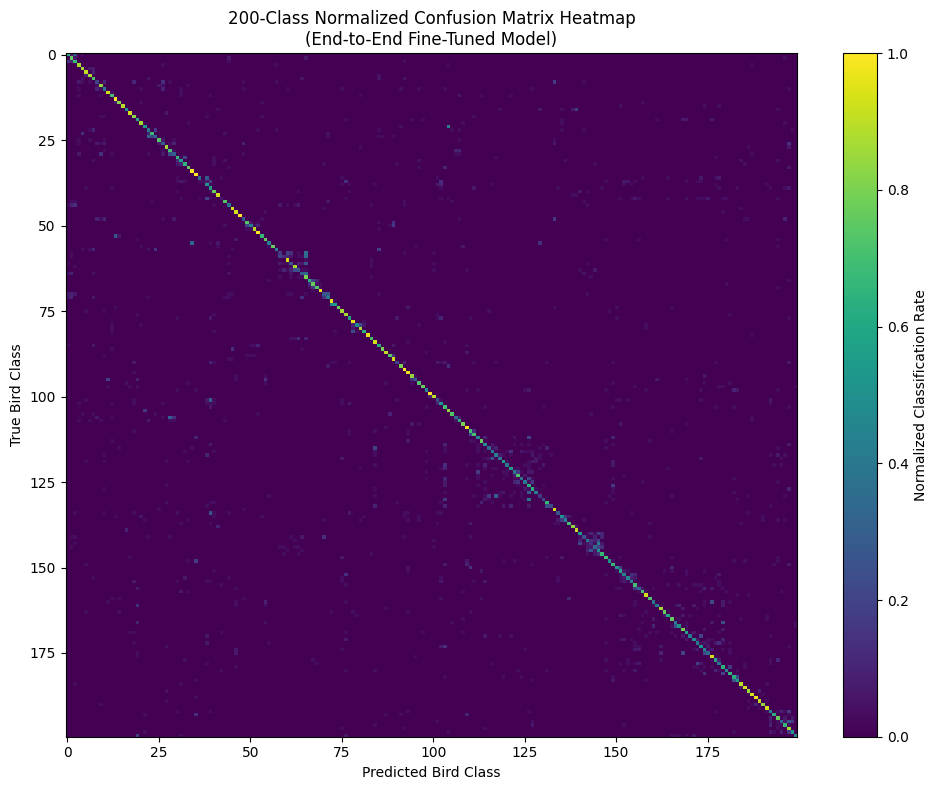

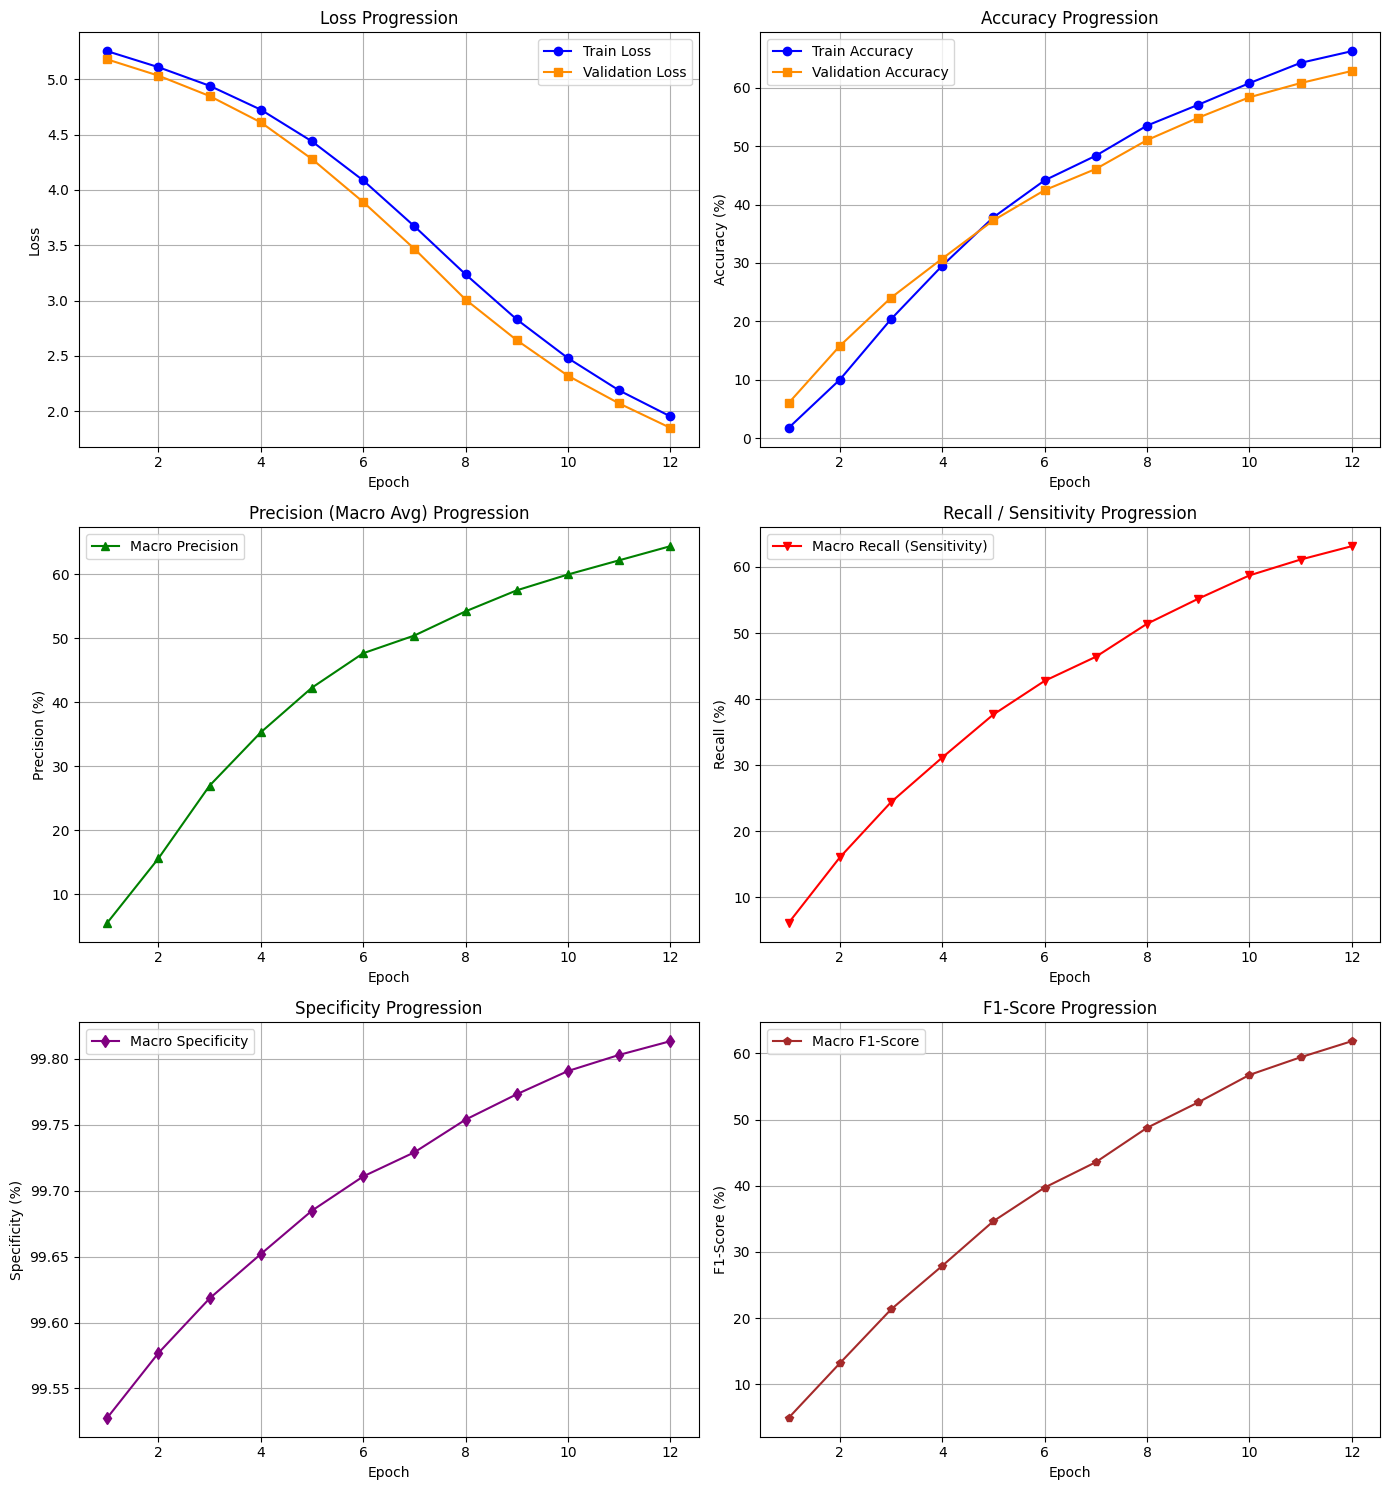

In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from tqdm.notebook import tqdm

# 1. Device Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Dataset Definition
class CUB200Dataset(Dataset):
    def __init__(self, base_dir, is_train=True, transform=None):
        self.base_dir = base_dir
        self.transform = transform

        images_txt_path = os.path.join(base_dir, "images.txt")
        split_txt_path = os.path.join(base_dir, "train_test_split.txt")
        labels_txt_path = os.path.join(base_dir, "image_class_labels.txt")

        images_df = pd.read_csv(images_txt_path, sep=" ", names=["image_id", "filepath"])
        split_df = pd.read_csv(split_txt_path, sep=" ", names=["image_id", "is_training_image"])
        labels_df = pd.read_csv(labels_txt_path, sep=" ", names=["image_id", "label"])

        merged = images_df.merge(split_df, on="image_id").merge(labels_df, on="image_id")
        target_split = 1 if is_train else 0
        self.data_subset = merged[merged["is_training_image"] == target_split].reset_index(drop=True)

    def __len__(self):
        return len(self.data_subset)

    def __getitem__(self, idx):
        row = self.data_subset.iloc[idx]
        img_path = os.path.join(self.base_dir, "images", row["filepath"])
        image = Image.open(img_path).convert("RGB")
        label = int(row["label"]) - 1
        if self.transform:
            image = self.transform(image)
        return image, label

# 3. Transforms & Dataloaders Setup
cub_base_dir = "/content/bird_dataset/CUB_200_2011"
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = CUB200Dataset(base_dir=cub_base_dir, is_train=True, transform=train_transform)
test_dataset = CUB200Dataset(base_dir=cub_base_dir, is_train=False, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# 4. Helper Training and Evaluation Functions
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    # Batch-level progress bar with leave=False to avoid cluttering
    for inputs, targets in tqdm(loader, desc="Training Batches", leave=False):
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
    return running_loss / total, 100. * correct / total

def evaluate_loss_acc(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
    return running_loss / total, 100. * correct / total

# 5. Initialize Model Architecture
print("Initializing pre-trained ResNet50 model...")
weights = models.ResNet50_Weights.DEFAULT
fresh_model = models.resnet50(weights=weights)
for param in fresh_model.parameters():
    param.requires_grad = True

num_features = fresh_model.fc.in_features
fresh_model.fc = nn.Linear(num_features, 200)
fresh_model = fresh_model.to(device)

# 6. Configure Parameter Groups for Differential Learning Rates
backbone_params = []
head_params = []
for name, param in fresh_model.named_parameters():
    if "fc" in name:
        head_params.append(param)
    else:
        backbone_params.append(param)

optimizer_diff = optim.SGD([
    {'params': backbone_params, 'lr': 1e-4},
    {'params': head_params, 'lr': 1e-3}
], momentum=0.9, weight_decay=1e-4)

criterion_diff = nn.CrossEntropyLoss()

# 7. Initialize Training Log History
fresh_history = {
    'train_loss': [],
    'train_acc': [],
    'test_loss': [],
    'test_acc': [],
    'test_precision': [],
    'test_recall': [],
    'test_f1': [],
    'test_specificity': []
}

target_fine_tune_epochs = 12
print("Starting end-to-end training process...")
total_start_time = time.time()

# Epoch-level progress bar using tqdm.notebook
for epoch in tqdm(range(target_fine_tune_epochs), desc="Overall Progress"):
    start_time = time.time()

    train_loss, train_acc = train_one_epoch(fresh_model, train_loader, criterion_diff, optimizer_diff, device)
    test_loss, test_acc = evaluate_loss_acc(fresh_model, test_loader, criterion_diff, device)

    fresh_model.eval()
    epoch_preds = []
    epoch_targets = []
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            outputs = fresh_model(inputs)
            _, predicted = outputs.max(1)
            epoch_preds.extend(predicted.cpu().numpy())
            epoch_targets.extend(targets.numpy())

    epoch_preds = np.array(epoch_preds)
    epoch_targets = np.array(epoch_targets)

    p, r, f1, _ = precision_recall_fscore_support(epoch_targets, epoch_preds, average='macro', zero_division=0)

    cm = confusion_matrix(epoch_targets, epoch_preds, labels=list(range(200)))
    specs = []
    for i in range(200):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        tn = cm.sum() - (tp + fp + fn)
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        specs.append(spec)

    fresh_history['train_loss'].append(train_loss)
    fresh_history['train_acc'].append(train_acc)
    fresh_history['test_loss'].append(test_loss)
    fresh_history['test_acc'].append(test_acc)
    fresh_history['test_precision'].append(p * 100)
    fresh_history['test_recall'].append(r * 100)
    fresh_history['test_f1'].append(f1 * 100)
    fresh_history['test_specificity'].append(np.mean(specs) * 100)

    elapsed = time.time() - start_time
    cumulative_elapsed = time.time() - total_start_time
    print(f"Epoch {epoch + 1}/{target_fine_tune_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
          f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
          f"Epoch Time: {elapsed:.1f}s | Total Training Time: {cumulative_elapsed:.1f}s\n")

total_duration = time.time() - total_start_time
print(f"Training complete! Total Elapsed Time: {total_duration:.1f} seconds.")

# Save model checkpoint to disk
torch.save({
    'model_state_dict': fresh_model.state_dict(),
    'optimizer_state_dict': optimizer_diff.state_dict(),
    'history': fresh_history
}, 'resnet50_fine_tuned_checkpoint.pth')
print("Checkpoint successfully saved to resnet50_fine_tuned_checkpoint.pth")

# --- 8. Graphical View of the Confusion Matrix ---
plt.figure(figsize=(10, 8))
final_cm = confusion_matrix(epoch_targets, epoch_preds, labels=list(range(200)))
row_sums = final_cm.sum(axis=1, keepdims=True)
normalized_cm = np.where(row_sums > 0, final_cm / row_sums, 0.0)
im = plt.imshow(normalized_cm, cmap='viridis', aspect='auto')
plt.colorbar(im, label='Normalized Classification Rate')
plt.title('200-Class Normalized Confusion Matrix Heatmap\n(End-to-End Fine-Tuned Model)')
plt.xlabel('Predicted Bird Class')
plt.ylabel('True Bird Class')
plt.tight_layout()
plt.show()

# --- 9. Graphs for Each Individual Evaluation Standard ---
epochs_range = list(range(1, target_fine_tune_epochs + 1))
fig, axs = plt.subplots(3, 2, figsize=(14, 15))
axs = axs.ravel()

# Plot Loss
axs[0].plot(epochs_range, fresh_history['train_loss'], label='Train Loss', color='blue', marker='o')
axs[0].plot(epochs_range, fresh_history['test_loss'], label='Validation Loss', color='darkorange', marker='s')
axs[0].set_title('Loss Progression')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Loss')
axs[0].legend()
axs[0].grid(True)

# Plot Accuracy
axs[1].plot(epochs_range, fresh_history['train_acc'], label='Train Accuracy', color='blue', marker='o')
axs[1].plot(epochs_range, fresh_history['test_acc'], label='Validation Accuracy', color='darkorange', marker='s')
axs[1].set_title('Accuracy Progression')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Accuracy (%)')
axs[1].legend()
axs[1].grid(True)

# Plot Precision
axs[2].plot(epochs_range, fresh_history['test_precision'], label='Macro Precision', color='green', marker='^')
axs[2].set_title('Precision (Macro Avg) Progression')
axs[2].set_xlabel('Epoch')
axs[2].set_ylabel('Precision (%)')
axs[2].legend()
axs[2].grid(True)

# Plot Recall/Sensitivity
axs[3].plot(epochs_range, fresh_history['test_recall'], label='Macro Recall (Sensitivity)', color='red', marker='v')
axs[3].set_title('Recall / Sensitivity Progression')
axs[3].set_xlabel('Epoch')
axs[3].set_ylabel('Recall (%)')
axs[3].legend()
axs[3].grid(True)

# Plot Specificity
axs[4].plot(epochs_range, fresh_history['test_specificity'], label='Macro Specificity', color='purple', marker='d')
axs[4].set_title('Specificity Progression')
axs[4].set_xlabel('Epoch')
axs[4].set_ylabel('Specificity (%)')
axs[4].legend()
axs[4].grid(True)

# Plot F1-Score
axs[5].plot(epochs_range, fresh_history['test_f1'], label='Macro F1-Score', color='brown', marker='p')
axs[5].set_title('F1-Score Progression')
axs[5].set_xlabel('Epoch')
axs[5].set_ylabel('F1-Score (%)')
axs[5].legend()
axs[5].grid(True)

plt.tight_layout()
plt.show()

In [5]:
import os
import torch
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim

checkpoint_path = 'resnet50_fine_tuned_checkpoint.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if os.path.exists(checkpoint_path):
    print(f"Found checkpoint: {checkpoint_path}. Restoring session variables...")

    # 1. Re-initialize model architecture
    fresh_model = models.resnet50(weights=None)
    num_features = fresh_model.fc.in_features
    fresh_model.fc = nn.Linear(num_features, 200)
    fresh_model = fresh_model.to(device)

    # 2. Configure Parameter Groups for Optimizer matching original setup
    backbone_params = []
    head_params = []
    for name, param in fresh_model.named_parameters():
        if "fc" in name:
            head_params.append(param)
        else:
            backbone_params.append(param)

    optimizer_diff = optim.SGD([
        {'params': backbone_params, 'lr': 1e-4},
        {'params': head_params, 'lr': 1e-3}
    ], momentum=0.9, weight_decay=1e-4)

    criterion_diff = nn.CrossEntropyLoss()

    # 3. Load saved state dictionary with weights_only=False to allow numpy structures in history
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    fresh_model.load_state_dict(checkpoint['model_state_dict'])
    optimizer_diff.load_state_dict(checkpoint['optimizer_state_dict'])
    fresh_history = checkpoint['history']

    print(f"Successfully loaded checkpoint! Resuming from epoch {len(fresh_history['train_loss'])}.")
else:
    print(f"Error: Checkpoint file '{checkpoint_path}' not found on disk. Please rerun the main training cell (f454ab32) first.")

Found checkpoint: resnet50_fine_tuned_checkpoint.pth. Restoring session variables...
Successfully loaded checkpoint! Resuming from epoch 12.


Resuming training from current in-memory model state.
Continuing end-to-end training for 5 additional epochs (Epoch 13 to 17)...


Additional Epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Training Batches:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 13/17 | Train Loss: 1.7473, Train Acc: 70.22% | Test Loss: 1.7016, Test Acc: 65.69% | Epoch Time: 126.4s | Total Segment Training Time: 126.4s



Training Batches:   0%|          | 0/188 [00:00<?, ?it/s]

...

Epoch 15/17 | Train Loss: 1.4745, Train Acc: 72.64% | Test Loss: 1.4976, Test Acc: 67.14% | Epoch Time: 134.2s | Total Segment Training Time: 385.3s



Training Batches:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 16/17 | Train Loss: 1.3514, Train Acc: 75.06% | Test Loss: 1.3846, Test Acc: 69.11% | Epoch Time: 123.8s | Total Segment Training Time: 509.1s



Training Batches:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 17/17 | Train Loss: 1.2808, Train Acc: 75.61% | Test Loss: 1.3370, Test Acc: 69.62% | Epoch Time: 125.3s | Total Segment Training Time: 634.4s

Additional training complete! Total Session Elapsed Time: 634.4 seconds.
Checkpoint successfully saved to resnet50_fine_tuned_checkpoint.pth


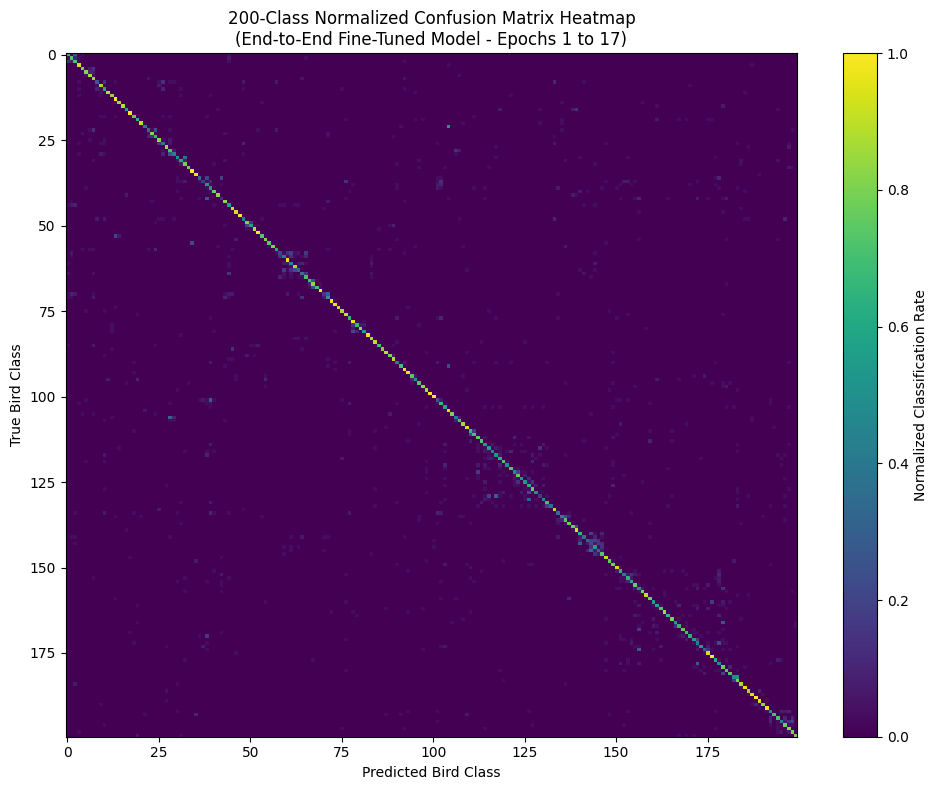

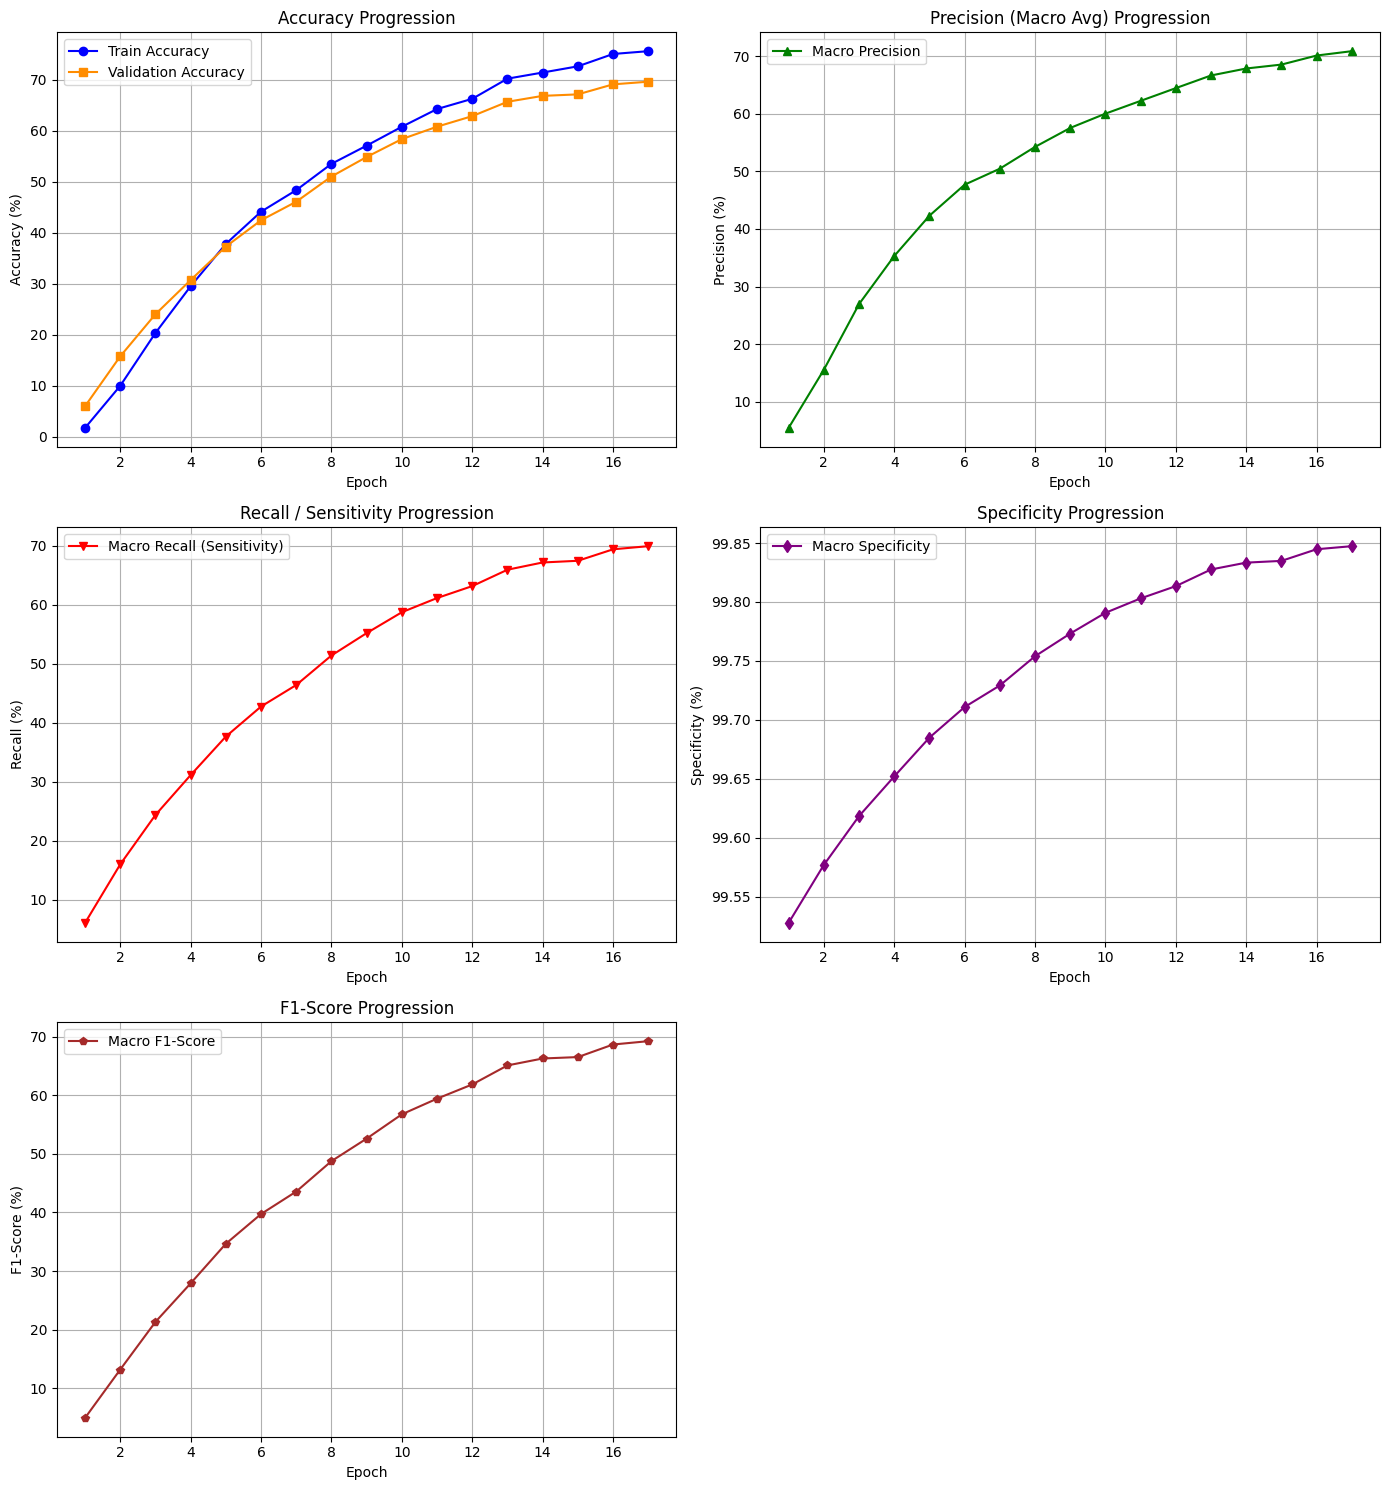

In [6]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
import sys
import torch
from tqdm.auto import tqdm

# Safety check using the correct variables initialized in cell f454ab32
if 'fresh_model' not in locals() or 'fresh_history' not in locals():
    print("Error: 'fresh_model' or 'fresh_history' is not found in the current runtime session.", file=sys.stderr)
    print("Please run the checkpoint restoration cell (209d1637) above first to load your saved model state.", file=sys.stderr)
else:
    # 1. Configuration for additional training epochs
    additional_epochs = 5
    current_total_epochs = len(fresh_history['train_loss'])
    target_epochs = current_total_epochs + additional_epochs

    print(f"Resuming training from current in-memory model state.")
    print(f"Continuing end-to-end training for {additional_epochs} additional epochs (Epoch {current_total_epochs + 1} to {target_epochs})...")

    total_start_time = time.time()

    # 2. Training Loop with Epoch-level progress bar
    for epoch in tqdm(range(current_total_epochs, target_epochs), desc="Additional Epochs"):
        start_time = time.time()

        # Train and evaluate one epoch using the pre-existing variables
        train_loss, train_acc = train_one_epoch(fresh_model, train_loader, criterion_diff, optimizer_diff, device)
        test_loss, test_acc = evaluate_loss_acc(fresh_model, test_loader, criterion_diff, device)

        # Evaluate metrics on validation set
        fresh_model.eval()
        epoch_preds = []
        epoch_targets = []
        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs = inputs.to(device)
                outputs = fresh_model(inputs)
                _, predicted = outputs.max(1)
                epoch_preds.extend(predicted.cpu().numpy())
                epoch_targets.extend(targets.numpy())

        epoch_preds = np.array(epoch_preds)
        epoch_targets = np.array(epoch_targets)

        # Calculate per-epoch validation metrics
        p, r, f1, _ = precision_recall_fscore_support(epoch_targets, epoch_preds, average='macro', zero_division=0)

        cm = confusion_matrix(epoch_targets, epoch_preds, labels=list(range(200)))
        specs = []
        for i in range(200):
            tp = cm[i, i]
            fp = cm[:, i].sum() - tp
            fn = cm[i, :].sum() - tp
            tn = cm.sum() - (tp + fp + fn)
            spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
            specs.append(spec)

        fresh_history['train_loss'].append(train_loss)
        fresh_history['train_acc'].append(train_acc)
        fresh_history['test_loss'].append(test_loss)
        fresh_history['test_acc'].append(test_acc)
        fresh_history['test_precision'].append(p * 100)
        fresh_history['test_recall'].append(r * 100)
        fresh_history['test_f1'].append(f1 * 100)
        fresh_history['test_specificity'].append(np.mean(specs) * 100)

        elapsed = time.time() - start_time
        cumulative_elapsed = time.time() - total_start_time
        print(f"Epoch {epoch + 1}/{target_epochs} | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
              f"Epoch Time: {elapsed:.1f}s | Total Segment Training Time: {cumulative_elapsed:.1f}s\n")

    total_duration = time.time() - total_start_time
    print(f"Additional training complete! Total Session Elapsed Time: {total_duration:.1f} seconds.")

    # Save checkpoint to avoid losing progress
    torch.save({
        'model_state_dict': fresh_model.state_dict(),
        'optimizer_state_dict': optimizer_diff.state_dict(),
        'history': fresh_history
    }, 'resnet50_fine_tuned_checkpoint.pth')
    print("Checkpoint successfully saved to resnet50_fine_tuned_checkpoint.pth")

    # --- 3. Normalized Confusion Matrix Heatmap ---
    plt.figure(figsize=(10, 8))
    final_cm = confusion_matrix(epoch_targets, epoch_preds, labels=list(range(200)))
    row_sums = final_cm.sum(axis=1, keepdims=True)
    normalized_cm = np.where(row_sums > 0, final_cm / row_sums, 0.0)
    im = plt.imshow(normalized_cm, cmap='viridis', aspect='auto')
    plt.colorbar(im, label='Normalized Classification Rate')
    plt.title('200-Class Normalized Confusion Matrix Heatmap\n(End-to-End Fine-Tuned Model - Epochs 1 to 17)')
    plt.xlabel('Predicted Bird Class')
    plt.ylabel('True Bird Class')
    plt.tight_layout()
    plt.show()

    # --- 4. Progression Curves for Evaluation Standards ---
    epochs_range = list(range(1, target_epochs + 1))
    fig, axs = plt.subplots(3, 2, figsize=(14, 15))
    axs = axs.ravel()

    # Plot Accuracy
    axs[0].plot(epochs_range, fresh_history['train_acc'], label='Train Accuracy', color='blue', marker='o')
    axs[0].plot(epochs_range, fresh_history['test_acc'], label='Validation Accuracy', color='darkorange', marker='s')
    axs[0].set_title('Accuracy Progression')
    axs[0].set_xlabel('Epoch')
    axs[0].set_ylabel('Accuracy (%)')
    axs[0].legend()
    axs[0].grid(True)

    # Plot Precision
    axs[1].plot(epochs_range, fresh_history['test_precision'], label='Macro Precision', color='green', marker='^')
    axs[1].set_title('Precision (Macro Avg) Progression')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Precision (%)')
    axs[1].legend()
    axs[1].grid(True)

    # Plot Recall/Sensitivity
    axs[2].plot(epochs_range, fresh_history['test_recall'], label='Macro Recall (Sensitivity)', color='red', marker='v')
    axs[2].set_title('Recall / Sensitivity Progression')
    axs[2].set_xlabel('Epoch')
    axs[2].set_ylabel('Recall (%)')
    axs[2].legend()
    axs[2].grid(True)

    # Plot Specificity
    axs[3].plot(epochs_range, fresh_history['test_specificity'], label='Macro Specificity', color='purple', marker='d')
    axs[3].set_title('Specificity Progression')
    axs[3].set_xlabel('Epoch')
    axs[3].set_ylabel('Specificity (%)')
    axs[3].legend()
    axs[3].grid(True)

    # Plot F1-Score
    axs[4].plot(epochs_range, fresh_history['test_f1'], label='Macro F1-Score', color='brown', marker='p')
    axs[4].set_title('F1-Score Progression')
    axs[4].set_xlabel('Epoch')
    axs[4].set_ylabel('F1-Score (%)')
    axs[4].legend()
    axs[4].grid(True)

    # Hide unused 6th subplot
    axs[5].axis('off')

    plt.tight_layout()
    plt.show()

In [7]:
import torch
from google.colab import files

# Define export file paths
weights_only_path = 'resnet50_cub200_weights.pth'
full_model_path = 'resnet50_cub200_final.pth'

print("Exporting model state dictionary...")
torch.save(fresh_model.state_dict(), weights_only_path)

print("Exporting full model architecture and weights...")
torch.save(fresh_model, full_model_path)

print(f"Export complete! Saved files to:\n - {weights_only_path} (Weights only)\n - {full_model_path} (Entire model structure and weights)")

try:
    print("Triggering file download for the complete model...")
    files.download(full_model_path)
except Exception as e:
    print("Automatic download trigger failed. You can find and download the exported files manually using the folder icon in Colab's left sidebar.")

Exporting model state dictionary...
Exporting full model architecture and weights...
Export complete! Saved files to:
 - resnet50_cub200_weights.pth (Weights only)
 - resnet50_cub200_final.pth (Entire model structure and weights)
Triggering file download for the complete model...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>